In [25]:
import os
from ensurepip import bootstrap
import warnings
from statistics import mean

from jupyter_builder.jupyterlab_semver import satisfies
from sklearn.impute import SimpleImputer
from optuna.trial import FixedTrial
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
import optuna
from sklearn.inspection import permutation_importance
import shap
from optuna.visualization import plot_param_importances, plot_optimization_history, plot_slice
import math


load_dotenv(find_dotenv(usecwd=True))
url = URL.create("postgresql+psycopg2",
    username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
    host="localhost", port=5433, database="adult")
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM adults", engine)
print(df.shape)
df.info()
df['workclass'] = df['workclass'].fillna('Private')
df['native_country'] = df['native_country'].fillna('United-States')


(32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education_num   32561 non-null  int64
 5   marital_status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital_gain    32561 non-null  int64
 11  capital_loss    32561 non-null  int64
 12  hours_per_week  32561 non-null  int64
 13  native_country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [4]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


<Axes: xlabel='hours_per_week'>

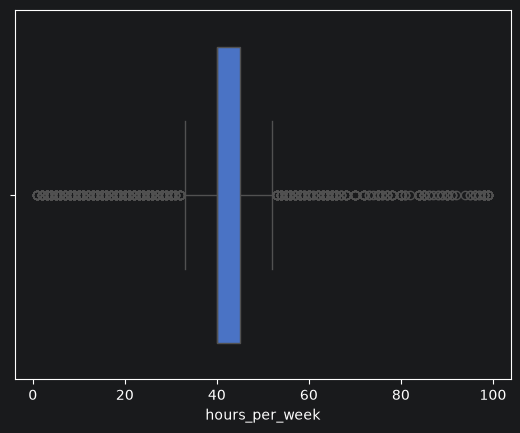

In [10]:

sns.boxplot(data=df, x = 'hours_per_week')

<Axes: xlabel='hours_per_week', ylabel='Proportion'>

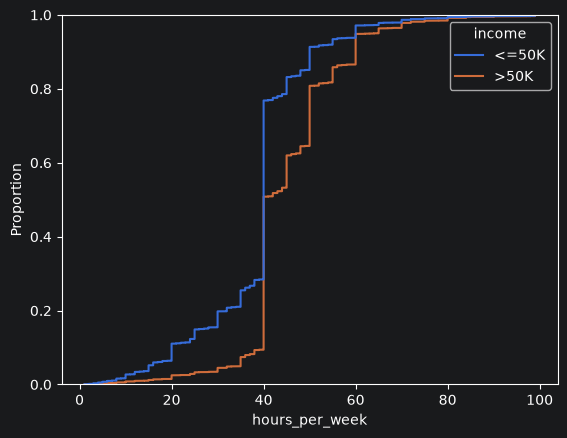

In [12]:
sns.ecdfplot(data=df, x = 'hours_per_week', hue='income')

proportion - доля, 40 часов в неделю, идет примерно 0.2 то есть 20% людей работают меньше 40 часов в неделю, и 40 часов ровно получатется до около 70%, 70-20 = 50% работают ровно 40 часов в неделю. около 60 часов в неделю работают +- 90 - 70 = 20% людей. И можно еще сказать то что 90% людей работают до 60 часов в неделю. остальные 10 работяги

In [28]:
top_6 = ['Prof-specialty',
    'Craft-repair',
    'Exec-managerial',
    'Adm-clerical',
    'Sales',
    'Other-service']
prods = df['occupation'].value_counts().loc[top_6]
prods = prods / prods.sum()
null_mask = df['occupation'].isna()
rng = np.random.default_rng(42)
df.loc[null_mask, 'occupation'] = rng.choice(top_6, size=null_mask.sum(), p=prods)

In [30]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64